# Actividad 6 | Evaluación y validación de riesgo crediticio

**Gestión de Proyectos de Inteligencia Artificial · Google Colab**

**Pregunta de análisis:** ¿qué tan bien podemos identificar clientes con incumplimiento de pago el mes siguiente a partir de su historial financiero?

**Dataset:** [Default of Credit Card Clients, Kaggle](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset) · Archivo `UCI_Credit_Card.csv` · 30,000 registros · 23 predictores originales.

**Objetivo experimental SMART:** alcanzar **ROC-AUC ≥ 0.77** y **recall de incumplimiento ≥ 0.70** durante un ciclo de evaluación de cuatro semanas, comprobando el resultado en un conjunto de prueba independiente. Es una **meta**, no una cifra ya observada.

**Diseño:** 60% entrenamiento + 20% validación de umbral + 20% prueba final; 5 folds de validación cruzada **solo** en entrenamiento; comparación contra baseline ingenuo y regresión logística, además de un algoritmo de boosting. El A/B es **una simulación retrospectiva** de asignación aleatoria, no un experimento operativo.

**Advertencia:** datos históricos de Taiwán (2005); no usar el modelo para decisiones crediticias reales. Se excluyen variables demográficas de los predictores y se reservan exclusivamente para exploración de posibles diferencias entre grupos.

## 1. Preparación del entorno

El experimento se ejecuta en CPU de Google Colab; **no requiere GPU**. Se instalan `kagglehub` y las librerías estadísticas. Ejecuta las celdas en orden para preservar la separación de los conjuntos.

In [ ]:
%pip -q install "kagglehub>=0.3,<1" "scikit-learn>=1.3,<2" "scipy>=1.11,<2" "pandas>=2,<3" "matplotlib>=3.7,<4" "joblib>=1.3,<2"

In [ ]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
from datetime import datetime, timezone

import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.stats import binomtest, fisher_exact
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    balanced_accuracy_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.figsize": (8, 5), "figure.dpi": 120})

SEMILLA = 42
N_FOLDS = 5
META_ROC_AUC = 0.77
META_RECALL = 0.70
COSTO_FALSO_NEGATIVO = 5.0    # Unidades ilustrativas, NO dinero real
COSTO_FALSO_POSITIVO = 1.0   # Modificable según datos operativos reales
N_BOOTSTRAP = 1000

SALIDA = Path("/content/actividad6_resultados" if Path("/content").exists() else "actividad6_resultados")
FIGURAS = SALIDA / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

np.random.seed(SEMILLA)
print("Entorno:", platform.python_version(), "| sklearn:", sklearn.__version__)
print("Directorio de resultados:", SALIDA.resolve())

Entorno: 3.13.16 | sklearn: 1.6.1
Directorio de resultados: /content/actividad6_resultados


## 2. Descarga verificable desde Kaggle y carga

Se descarga la versión pública desde Kaggle mediante `kagglehub`. Si Kaggle solicita autenticación o la descarga falla, en Colab podrás **subir manualmente** `UCI_Credit_Card.csv` obtenido del enlace anterior. No se generan datos ficticios como reemplazo.

In [ ]:
DATASET_KAGGLE = "uciml/default-of-credit-card-clients-dataset"
NOMBRE_CSV = "UCI_Credit_Card.csv"

try:
    carpeta_kaggle = Path(kagglehub.dataset_download(DATASET_KAGGLE))
    archivos_csv = sorted(carpeta_kaggle.rglob(NOMBRE_CSV))
    if not archivos_csv:
        raise FileNotFoundError(f"No se encontró {NOMBRE_CSV} en {carpeta_kaggle}")
    ruta_csv = archivos_csv[0]
except Exception as error_descarga:
    print("Descarga automática no disponible:", str(error_descarga)[:350])
    if not Path("/content").exists():
        raise RuntimeError("Ejecuta el notebook en Colab o proporciona el CSV original localmente.") from error_descarga
    from google.colab import files
    print(f"Sube el archivo original {NOMBRE_CSV}, descargado de Kaggle.")
    archivos_subidos = files.upload()
    if NOMBRE_CSV not in archivos_subidos:
        raise FileNotFoundError(f"Debes subir exactamente {NOMBRE_CSV}.")
    ruta_csv = Path(NOMBRE_CSV)

huella_archivo = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
datos_originales = pd.read_csv(ruta_csv)
datos_originales.columns = datos_originales.columns.str.strip()

VARIABLE_OBJETIVO = "default.payment.next.month"
COLUMNAS_ESPERADAS = {"ID", "LIMIT_BAL", "PAY_0", "BILL_AMT1", VARIABLE_OBJETIVO}
if not COLUMNAS_ESPERADAS.issubset(set(datos_originales.columns)):
    raise ValueError(f"Esquema inesperado. Columnas: {datos_originales.columns.tolist()}")
if datos_originales[VARIABLE_OBJETIVO].isna().any():
    raise ValueError("La etiqueta objetivo contiene nulos; revisar el origen del archivo.")
if set(datos_originales[VARIABLE_OBJETIVO].unique()) != {0, 1}:
    raise ValueError("La variable objetivo debe contener las clases 0 y 1.")
if datos_originales["ID"].duplicated().any():
    raise ValueError("Hay identificadores ID duplicados; revisar antes de entrenar.")

print("Archivo:", ruta_csv)
print("Filas y columnas:", datos_originales.shape)
print("SHA256:", huella_archivo)
display(datos_originales.head(5))

Using Colab cache for faster access to the 'default-of-credit-card-clients-dataset' dataset.
Archivo: /kaggle/input/default-of-credit-card-clients-dataset/UCI_Credit_Card.csv
Filas y columnas: (30000, 25)
SHA256: a0f0ab49d6326671d6cd83be5c88dcf18007025fe9a53ecd699119c871176ca1


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## 3. Calidad, distribución de la variable objetivo y exclusiones

Se conserva la clase original `1 = incumplimiento`. No se aplica balanceo sintético sobre la muestra de prueba. `ID` identifica a la persona y no debe usarse como predictor. `SEX`, `EDUCATION`, `MARRIAGE` y `AGE` se excluyen del entrenamiento para reducir el uso directo de atributos demográficos; excluirlos **no garantiza ausencia de sesgo**.

Predictores empleados: 19
Duplicados exactos (incluyendo ID): 0
Distribución de la variable objetivo:


,registros,porcentaje
default.payment.next.month,,
0,23364,77.88
1,6636,22.12


,tipo,nulos,porcentaje_nulos,valores_unicos
ID,int64,0,0.0,30000
LIMIT_BAL,float64,0,0.0,81
SEX,int64,0,0.0,2
EDUCATION,int64,0,0.0,7
MARRIAGE,int64,0,0.0,4
AGE,int64,0,0.0,56
PAY_0,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


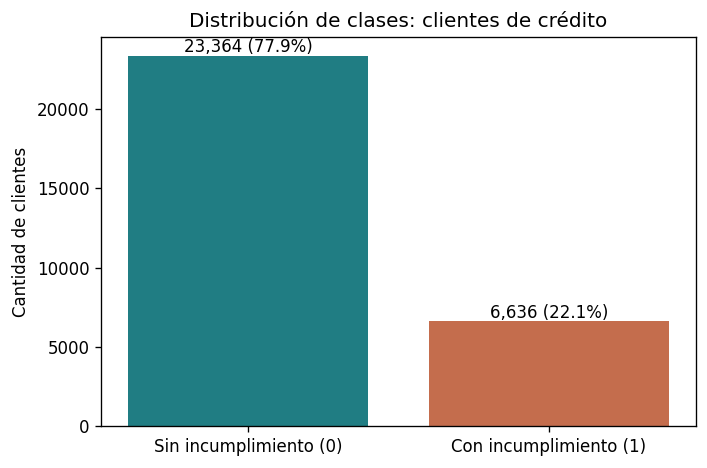

In [ ]:
calidad = pd.DataFrame({
    "tipo": datos_originales.dtypes.astype(str),
    "nulos": datos_originales.isna().sum(),
    "porcentaje_nulos": 100 * datos_originales.isna().mean(),
    "valores_unicos": datos_originales.nunique(),
}).sort_values("porcentaje_nulos", ascending=False)
exclusiones = ["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", VARIABLE_OBJETIVO]
columnas_modelo = [c for c in datos_originales.columns if c not in exclusiones]

# Usamos solo predictores cuantitativos históricos de crédito y comportamiento de pago.
X = datos_originales[columnas_modelo].apply(pd.to_numeric, errors="raise").copy()
y = datos_originales[VARIABLE_OBJETIVO].astype(int).copy()
auditoria = datos_originales[["SEX", "AGE"]].copy()

print("Predictores empleados:", len(columnas_modelo))
print("Duplicados exactos (incluyendo ID):", int(datos_originales.duplicated().sum()))
print("Distribución de la variable objetivo:")
display(pd.DataFrame({"registros": y.value_counts().sort_index(), "porcentaje": (100*y.value_counts(normalize=True).sort_index()).round(2)}))
display(calidad)

fig, ax = plt.subplots(figsize=(6, 4))
frecuencias = y.value_counts().reindex([0, 1], fill_value=0)
ax.bar(["Sin incumplimiento (0)", "Con incumplimiento (1)"], frecuencias, color=["#207d83", "#c46d4d"])
for idx, val in enumerate(frecuencias):
    ax.text(idx, val + 200, f"{int(val):,} ({val/len(y):.1%})", ha="center")
ax.set_title("Distribución de clases: clientes de crédito")
ax.set_ylabel("Cantidad de clientes")
fig.tight_layout()
fig.savefig(FIGURAS / "01_distribucion_clases.png", bbox_inches="tight")
plt.show()

## 4. División 60 / 20 / 20, estratificada y reproducible

- **Entrenamiento:** ajuste de parámetros y validación cruzada.
- **Validación:** elección del umbral de alerta con la meta de recall y los costos supuestos.
- **Prueba:** evaluación final, intervalos e inferencia retrospectiva A/B. No se utiliza para seleccionar hiperparámetros o umbral.

In [ ]:
indices = np.arange(len(y))
idx_desarrollo, idx_prueba = train_test_split(indices, test_size=0.20, stratify=y, random_state=SEMILLA)
idx_entreno, idx_validacion = train_test_split(
    idx_desarrollo, test_size=0.25, stratify=y.iloc[idx_desarrollo], random_state=SEMILLA
)

X_train, y_train = X.iloc[idx_entreno], y.iloc[idx_entreno]
X_val, y_val = X.iloc[idx_validacion], y.iloc[idx_validacion]
X_test, y_test = X.iloc[idx_prueba], y.iloc[idx_prueba]

distribuciones = pd.DataFrame([
    {"conjunto": nombre, "registros": len(etiquetas), "incumplimientos": int(etiquetas.sum()), "tasa_incumplimiento": etiquetas.mean()}
    for nombre, etiquetas in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]
])
print("Conjuntos sin traslape:", not (set(idx_entreno)&set(idx_validacion) or set(idx_entreno)&set(idx_prueba) or set(idx_validacion)&set(idx_prueba)))
display(distribuciones.style.format({"tasa_incumplimiento": "{:.2%}"}))
assert len(set(np.r_[idx_entreno, idx_validacion, idx_prueba])) == len(y)

Conjuntos sin traslape: True


,conjunto,registros,incumplimientos,tasa_incumplimiento
0,Entrenamiento,18000,3982,22.12%
1,Validación,6000,1327,22.12%
2,Prueba,6000,1327,22.12%


## 5. Modelos, baseline y búsqueda de hiperparámetros

El baseline ingenuo predice la frecuencia histórica de la clase positiva y usa umbral 0.50. Se entrenan **regresión logística** (interpretable) y **gradient boosting** (no lineal). Los predictores se imputan dentro de los pipelines para evitar fuga de información entre folds.

Los 5 folds pertenecen únicamente al entrenamiento; el ranking se decide por ROC-AUC promedio de CV, sin consultar la prueba.

In [ ]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
metricas_cv = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1_umbral_05": "f1"}

pipeline_logistico = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1500, solver="lbfgs", random_state=SEMILLA)),
])
pipeline_boosting = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("modelo", HistGradientBoostingClassifier(random_state=SEMILLA, early_stopping=False)),
])

configuraciones = {
    "Regresión logística": (
        pipeline_logistico,
        {"modelo__C": [0.1, 1.0, 10.0]},
    ),
    "Gradient Boosting": (
        pipeline_boosting,
        {"modelo__learning_rate": [0.05, 0.10],
         "modelo__max_leaf_nodes": [15, 31],
         "modelo__max_iter": [120],
         "modelo__min_samples_leaf": [40]},
    ),
}

resultados_cv = []
modelos_ajustados = {}

for nombre, (pipeline, parametros) in configuraciones.items():
    print(f"Optimizando {nombre}...")
    busqueda = GridSearchCV(
        estimator=pipeline, param_grid=parametros, scoring=metricas_cv,
        refit="roc_auc", cv=cv, n_jobs=-1, error_score="raise",
        return_train_score=False,
    )
    busqueda.fit(X_train, y_train)
    modelos_ajustados[nombre] = busqueda.best_estimator_
    fila_mejor = busqueda.cv_results_
    posicion = busqueda.best_index_
    resultados_cv.append({
        "modelo": nombre,
        "roc_auc_media_cv": float(fila_mejor["mean_test_roc_auc"][posicion]),
        "roc_auc_desviacion_cv": float(fila_mejor["std_test_roc_auc"][posicion]),
        "pr_auc_media_cv": float(fila_mejor["mean_test_pr_auc"][posicion]),
        "f1_05_media_cv": float(fila_mejor["mean_test_f1_umbral_05"][posicion]),
        "mejores_hiperparametros": json.dumps(busqueda.best_params_, ensure_ascii=False),
    })

baseline_ingenuo = DummyClassifier(strategy="prior")
baseline_cv = cross_validate(
    baseline_ingenuo, X_train, y_train, scoring=metricas_cv, cv=cv, n_jobs=-1
)
resultados_cv.append({
    "modelo": "Baseline sin modelo (prior)",
    "roc_auc_media_cv": float(np.mean(baseline_cv["test_roc_auc"])),
    "roc_auc_desviacion_cv": float(np.std(baseline_cv["test_roc_auc"])),
    "pr_auc_media_cv": float(np.mean(baseline_cv["test_pr_auc"])),
    "f1_05_media_cv": float(np.mean(baseline_cv["test_f1_umbral_05"])),
    "mejores_hiperparametros": "Sin ajuste",
})
baseline_ingenuo.fit(X_train, y_train)

comparacion_cv = pd.DataFrame(resultados_cv).sort_values("roc_auc_media_cv", ascending=False).reset_index(drop=True)
nombre_ganador_cv = max(modelos_ajustados, key=lambda n: comparacion_cv.set_index("modelo").loc[n, "roc_auc_media_cv"])
modelo_ganador = modelos_ajustados[nombre_ganador_cv]
print("Modelo candidato seleccionado EXCLUSIVAMENTE por CV:", nombre_ganador_cv)
display(comparacion_cv)

Optimizando Regresión logística...
Optimizando Gradient Boosting...
Modelo candidato seleccionado EXCLUSIVAMENTE por CV: Gradient Boosting


,modelo,roc_auc_media_cv,roc_auc_desviacion_cv,pr_auc_media_cv,f1_05_media_cv,mejores_hiperparametros
0,Gradient Boosting,0.781603,0.001568,0.560755,0.475275,"{""modelo__learning_rate"": 0.05, ""modelo__max_i..."
1,Regresión logística,0.727750,0.009390,0.510627,0.374001,"{""modelo__C"": 0.1}"
2,Baseline sin modelo (prior),0.500000,0.000000,0.221222,0.000000,Sin ajuste


## 6. Elección del umbral en validación (sin prueba)

La alerta se activa si `probabilidad_incumplimiento >= umbral`. El umbral 0.50 no es necesariamente óptimo cuando el costo de omitir a un cliente moroso supera al costo de revisar preventivamente a uno que sí paga.

Se evalúan valores de 0.05 a 0.95 y se elige el de **menor costo supuesto** entre los que tienen recall ≥ 70% en validación. Si ninguno satisface la restricción, se informa y se elige solamente el umbral de menor costo ilustrativo.

In [ ]:
def metricas_clasificacion(etiquetas_reales, probabilidades, umbral=0.50):
    reales = np.asarray(etiquetas_reales, dtype=int)
    probabilidades = np.asarray(probabilidades, dtype=float)
    predichas = (probabilidades >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(reales, predichas, labels=[0, 1]).ravel()
    return {
        "umbral": float(umbral), "n": int(len(reales)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "accuracy": float(accuracy_score(reales, predichas)),
        "balanced_accuracy": float(balanced_accuracy_score(reales, predichas)),
        "precision": float(precision_score(reales, predichas, zero_division=0)),
        "recall": float(recall_score(reales, predichas, zero_division=0)),
        "f1": float(f1_score(reales, predichas, zero_division=0)),
        "fpr": float(fp / (fp + tn)) if (fp + tn) else 0.0,
        "tasa_alertas": float(predichas.mean()),
        "roc_auc": float(roc_auc_score(reales, probabilidades)),
        "pr_auc": float(average_precision_score(reales, probabilidades)),
        "brier": float(brier_score_loss(reales, probabilidades)),
        "costo_total_ilustrativo": float(COSTO_FALSO_NEGATIVO * fn + COSTO_FALSO_POSITIVO * fp),
        "costo_por_1000": float(1000 * (COSTO_FALSO_NEGATIVO * fn + COSTO_FALSO_POSITIVO * fp) / len(reales)),
    }

prob_val = modelo_ganador.predict_proba(X_val)[:, 1]
umbrales_candidatos = np.round(np.linspace(0.05, 0.95, 91), 2)
tabla_umbrales = pd.DataFrame([
    metricas_clasificacion(y_val, prob_val, umbral) for umbral in umbrales_candidatos
])
elegibles = tabla_umbrales.loc[tabla_umbrales["recall"] >= META_RECALL].copy()
restriccion_satisfecha = not elegibles.empty
if elegibles.empty:
    elegibles = tabla_umbrales.copy()

mejor_fila = elegibles.sort_values(
    ["costo_total_ilustrativo", "fpr", "umbral"], ascending=[True, True, False]
).iloc[0]
umbral_optimo = float(mejor_fila["umbral"])

print(f"Umbral seleccionado con VALIDACIÓN: {umbral_optimo:.2f}")
print(f"Recall validación: {mejor_fila['recall']:.2%} | Meta cumplida: {restriccion_satisfecha}")
print("Costos supuestos de FN/FP:", COSTO_FALSO_NEGATIVO, COSTO_FALSO_POSITIVO)
display(tabla_umbrales.loc[tabla_umbrales["umbral"].isin([0.50, umbral_optimo]), [
    "umbral", "precision", "recall", "f1", "fpr", "costo_por_1000"
]])

tabla_umbrales.to_csv(SALIDA / "resultados_umbrales_validacion.csv", index=False)

Umbral seleccionado con VALIDACIÓN: 0.14
Recall validación: 82.06% | Meta cumplida: True
Costos supuestos de FN/FP: 5.0 1.0


,umbral,precision,recall,f1,fpr,costo_por_1000
9,0.14,0.341808,0.820648,0.482606,0.448748,547.833333
45,0.50,0.689706,0.353429,0.467364,0.045153,750.166667


## 7. Evaluación única en prueba y matrices de confusión

Una vez fijados **modelo e hiperparámetros mediante CV** y **umbral mediante validación**, se evalúa la prueba independiente. La regresión logística a 0.50 representa la política A de comparación; el modelo seleccionado con umbral óptimo representa la política B. El baseline ingenuo muestra por qué accuracy aislada es insuficiente.

RESULTADOS EN CONJUNTO DE PRUEBA INDEPENDIENTE


,politica,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,tp,fp,fn,tn,costo_por_1000
0,Baseline ingenuo | 0.50,0.779,0.000,0.000,0.000,0.500,0.221,0.000,0,0,1327,4673,1105.833
1,Logística | 0.50 (A),0.811,0.700,0.252,0.370,0.708,0.493,0.031,334,143,993,4530,851.333
2,Boosting | 0.50,0.820,0.674,0.356,0.466,0.777,0.553,0.049,473,229,854,4444,749.833
3,Seleccionado CV | 0.14 (B),0.595,0.331,0.815,0.471,0.777,0.553,0.467,1082,2184,245,2489,568.167


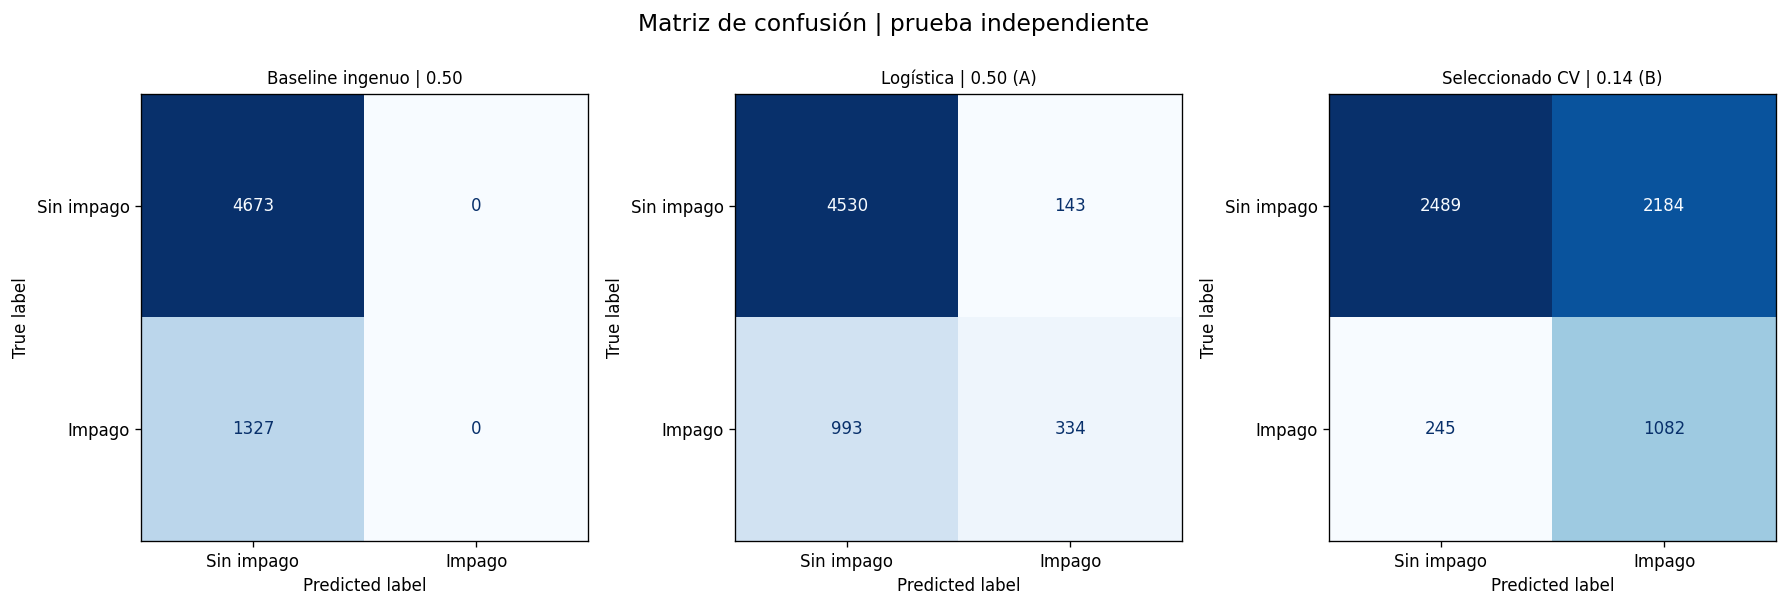

In [ ]:
prob_test_dummy = baseline_ingenuo.predict_proba(X_test)[:, 1]
prob_test_log = modelos_ajustados["Regresión logística"].predict_proba(X_test)[:, 1]
prob_test_boost = modelos_ajustados["Gradient Boosting"].predict_proba(X_test)[:, 1]
prob_test_ganador = modelo_ganador.predict_proba(X_test)[:, 1]

politicas = {
    "Baseline ingenuo | 0.50": (prob_test_dummy, 0.50),
    "Logística | 0.50 (A)": (prob_test_log, 0.50),
    "Boosting | 0.50": (prob_test_boost, 0.50),
    f"Seleccionado CV | {umbral_optimo:.2f} (B)": (prob_test_ganador, umbral_optimo),
}
resumen_test = pd.DataFrame([
    {"politica": nombre, **metricas_clasificacion(y_test, prob, umbral)}
    for nombre, (prob, umbral) in politicas.items()
])

print("RESULTADOS EN CONJUNTO DE PRUEBA INDEPENDIENTE")
display(resumen_test[[
    "politica", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "fpr", "tp", "fp", "fn", "tn", "costo_por_1000"
]].style.format({c: "{:.3f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "fpr", "costo_por_1000"]}))

resumen_test.to_csv(SALIDA / "comparacion_modelos_prueba.csv", index=False)
comparacion_cv.to_csv(SALIDA / "comparacion_validacion_cruzada.csv", index=False)

graficar_politicas = ["Baseline ingenuo | 0.50", "Logística | 0.50 (A)", f"Seleccionado CV | {umbral_optimo:.2f} (B)"]
fig, axes = plt.subplots(1, len(graficar_politicas), figsize=(15, 4.8))
for ax, nombre in zip(axes, graficar_politicas):
    probabilidades, corte = politicas[nombre]
    pred = (probabilidades >= corte).astype(int)
    matriz = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=["Sin impago", "Impago"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nombre, fontsize=10)
fig.suptitle("Matriz de confusión | prueba independiente", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURAS / "02_matrices_confusion.png", bbox_inches="tight")
plt.show()

## 8. Curvas ROC, precisión-recall y efecto del umbral

ROC-AUC mide el ordenamiento entre positivos y negativos sin depender del corte; la curva PR y el recall ofrecen un complemento particularmente útil cuando la clase de incumplimiento es minoritaria. Un ajuste de umbral **no modifica** la curva ROC del mismo conjunto de probabilidades, solo su punto operativo.

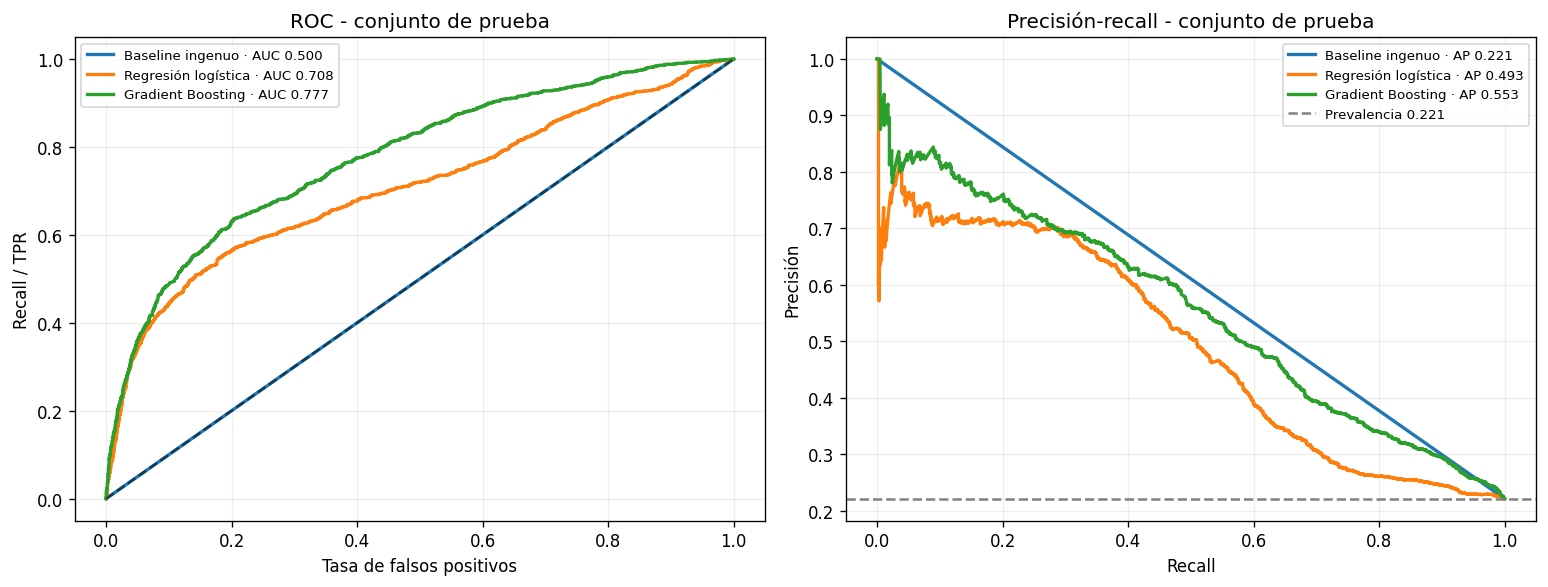

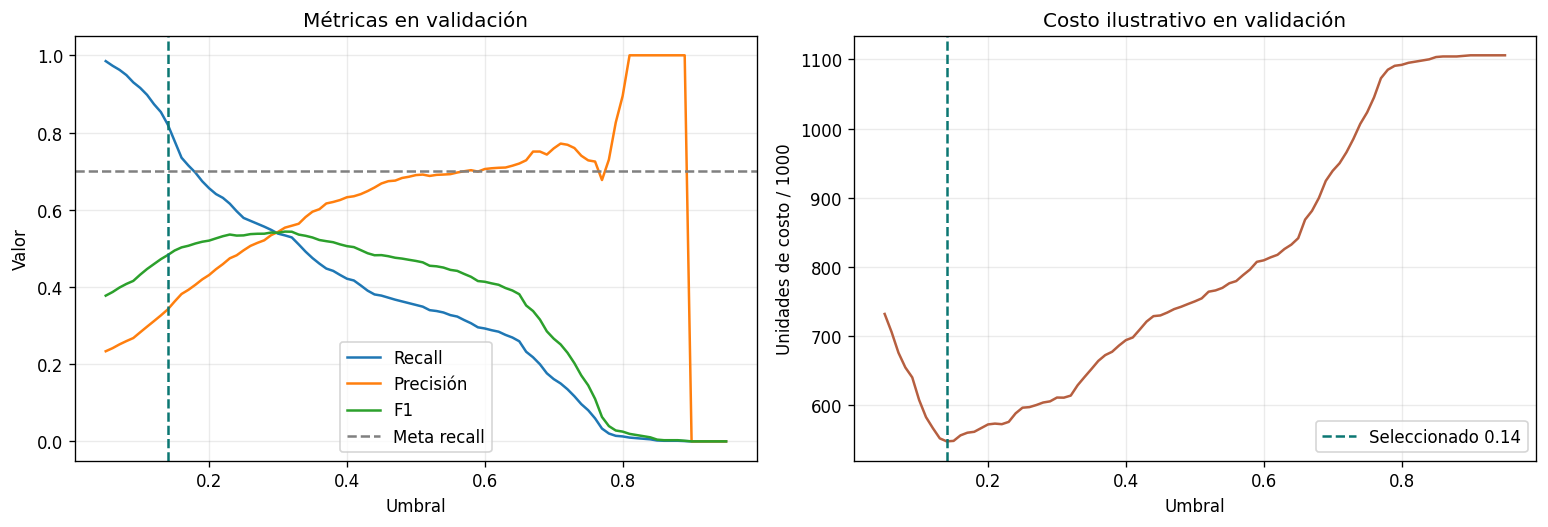

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, prob in [
    ("Baseline ingenuo", prob_test_dummy),
    ("Regresión logística", prob_test_log),
    ("Gradient Boosting", prob_test_boost),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    precision_curva, recall_curva, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, lw=2, label=f"{nombre} · AUC {roc_auc_score(y_test, prob):.3f}")
    axes[1].plot(recall_curva, precision_curva, lw=2, label=f"{nombre} · AP {average_precision_score(y_test, prob):.3f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Recall / TPR", title="ROC - conjunto de prueba")
axes[1].axhline(float(y_test.mean()), color="gray", linestyle="--", label=f"Prevalencia {y_test.mean():.3f}")
axes[1].set(xlabel="Recall", ylabel="Precisión", title="Precisión-recall - conjunto de prueba")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURAS / "03_curvas_roc_pr.png", bbox_inches="tight")
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].plot(tabla_umbrales["umbral"], tabla_umbrales["recall"], label="Recall")
ejes[0].plot(tabla_umbrales["umbral"], tabla_umbrales["precision"], label="Precisión")
ejes[0].plot(tabla_umbrales["umbral"], tabla_umbrales["f1"], label="F1")
ejes[0].axhline(META_RECALL, linestyle="--", color="gray", label="Meta recall")
ejes[0].set(xlabel="Umbral", ylabel="Valor", title="Métricas en validación")
ejes[0].legend()
ejes[1].plot(tabla_umbrales["umbral"], tabla_umbrales["costo_por_1000"], color="#b65f40")
for ax in ejes:
    ax.axvline(umbral_optimo, color="#0b7772", linestyle="--", label=f"Seleccionado {umbral_optimo:.2f}")
    ax.grid(alpha=0.25)
ejes[1].set(xlabel="Umbral", ylabel="Unidades de costo / 1000", title="Costo ilustrativo en validación")
ejes[1].legend()
fig.tight_layout()
fig.savefig(FIGURAS / "04_analisis_umbral.png", bbox_inches="tight")
plt.show()

## 9. Contraste estadístico pareado entre políticas A y B

Se utiliza la misma muestra de prueba para comparar aciertos y errores de A (logística 0.50) y B (modelo seleccionado con umbral ajustado). La prueba exacta de McNemar analiza **discordancias en clasificación correcta**, no diferencias de ROC-AUC ni costos. Una banda bootstrap pareada cuantifica la diferencia de AUC. Un `p` pequeño no equivale automáticamente a utilidad de negocio.

In [ ]:
reales_test = y_test.to_numpy()
pred_a_todos = (prob_test_log >= 0.50).astype(int)
pred_b_todos = (prob_test_ganador >= umbral_optimo).astype(int)
correcta_a = pred_a_todos == reales_test
correcta_b = pred_b_todos == reales_test
solo_a_correcta = int((correcta_a & ~correcta_b).sum())
solo_b_correcta = int((~correcta_a & correcta_b).sum())
discordancias = solo_a_correcta + solo_b_correcta
p_mcnemar = float(binomtest(solo_a_correcta, discordancias, p=0.5).pvalue) if discordancias else 1.0

rng_boot = np.random.default_rng(SEMILLA)
diferencias_auc = []
for _ in range(N_BOOTSTRAP):
    m = rng_boot.integers(0, len(reales_test), size=len(reales_test))
    if np.unique(reales_test[m]).size < 2:
        continue
    diferencias_auc.append(
        roc_auc_score(reales_test[m], prob_test_ganador[m])
        - roc_auc_score(reales_test[m], prob_test_log[m])
    )
intervalo_auc = np.quantile(diferencias_auc, [0.025, 0.975])
delta_auc = roc_auc_score(reales_test, prob_test_ganador) - roc_auc_score(reales_test, prob_test_log)
print("McNemar exacto (aciertos pareados, exploratorio)")
print("Solo A acierta:", solo_a_correcta, "| Solo B acierta:", solo_b_correcta, "| p:", f"{p_mcnemar:.6g}")
print(f"Δ ROC-AUC (B-A): {delta_auc:+.4f} | IC bootstrap 95%: [{intervalo_auc[0]:+.4f}, {intervalo_auc[1]:+.4f}]")

McNemar exacto (aciertos pareados, exploratorio)
Solo A acierta: 2041 | Solo B acierta: 748 | p: 2.79175e-137
Δ ROC-AUC (B-A): +0.0698 | IC bootstrap 95%: [+0.0562, +0.0836]


## 10. Diseño de la prueba A/B y simulación retrospectiva

**Política A (control):** regresión logística con corte fijo 0.50.

**Política B (tratamiento):** modelo elegido por CV y corte optimizado en validación.

A cada observación de prueba se asigna aleatoriamente A o B, aproximadamente 50/50. Se evalúa únicamente la política asignada; se reportan recalls, tasa de alertas y costo supuesto por 1,000 clientes. También se contrasta el recall con una prueba exacta de Fisher y se estiman intervalos bootstrap para diferencias de costo. **Esto es una simulación offline con resultados históricos ya conocidos:** no ejecuta una intervención, no mide mora evitada ni permite atribuir resultados causales de operación.

En un experimento real harían falta autorización, aleatorización operativa previa, protocolo de atención, indicadores de efectos adversos y seguimiento temporal de resultados.

In [ ]:
rng_ab = np.random.default_rng(2026)
asignacion_b = rng_ab.random(len(reales_test)) < 0.5

def costo_por_observacion(reales, predichas):
    reales = np.asarray(reales, dtype=int)
    predichas = np.asarray(predichas, dtype=int)
    return COSTO_FALSO_NEGATIVO * ((reales == 1) & (predichas == 0)) + COSTO_FALSO_POSITIVO * ((reales == 0) & (predichas == 1))

df_ab = pd.DataFrame({
    "grupo": np.where(asignacion_b, "B", "A"),
    "real": reales_test,
    "prediccion_asignada": np.where(asignacion_b, pred_b_todos, pred_a_todos),
})
df_ab["costo_ilustrativo"] = costo_por_observacion(df_ab["real"], df_ab["prediccion_asignada"])

registros_ab = []
for grupo in ["A", "B"]:
    sub = df_ab.loc[df_ab["grupo"] == grupo]
    tn, fp, fn, tp = confusion_matrix(sub["real"], sub["prediccion_asignada"], labels=[0, 1]).ravel()
    registros_ab.append({
        "grupo": grupo, "n": int(len(sub)), "positivos_reales": int(sub["real"].sum()),
        "prevalencia": float(sub["real"].mean()),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "recall": float(recall_score(sub["real"], sub["prediccion_asignada"], zero_division=0)),
        "precision": float(precision_score(sub["real"], sub["prediccion_asignada"], zero_division=0)),
        "tasa_alertas": float(sub["prediccion_asignada"].mean()),
        "costo_por_1000": float(1000 * sub["costo_ilustrativo"].mean()),
    })
resultado_ab = pd.DataFrame(registros_ab).set_index("grupo")
print("A/B RETROSPECTIVO - SOLO DEMOSTRACIÓN METODOLÓGICA")
display(resultado_ab)

fisher_odds, p_fisher = fisher_exact([
    [int(resultado_ab.loc["B", "tp"]), int(resultado_ab.loc["B", "fn"])],
    [int(resultado_ab.loc["A", "tp"]), int(resultado_ab.loc["A", "fn"])],
], alternative="two-sided")

muestra_a = df_ab.loc[df_ab["grupo"] == "A", "costo_ilustrativo"].to_numpy()
muestra_b = df_ab.loc[df_ab["grupo"] == "B", "costo_ilustrativo"].to_numpy()
rng_ic = np.random.default_rng(2027)
dif_costos = np.empty(N_BOOTSTRAP)
for i in range(N_BOOTSTRAP):
    costo_a = rng_ic.choice(muestra_a, size=len(muestra_a), replace=True).mean()
    costo_b = rng_ic.choice(muestra_b, size=len(muestra_b), replace=True).mean()
    dif_costos[i] = 1000 * (costo_b - costo_a)
ic_costos = np.quantile(dif_costos, [0.025, 0.975])
delta_costo = float(resultado_ab.loc["B", "costo_por_1000"] - resultado_ab.loc["A", "costo_por_1000"])
print(f"Recall B-A: {resultado_ab.loc['B', 'recall'] - resultado_ab.loc['A', 'recall']:+.2%}")
print(f"Fisher exacto en positivos (exploratorio): p={p_fisher:.6g}")
print(f"Costo por 1000, B-A: {delta_costo:+.2f} | IC bootstrap 95% [{ic_costos[0]:+.2f}, {ic_costos[1]:+.2f}]")

resultado_ab.to_csv(SALIDA / "simulacion_ab.csv")

A/B RETROSPECTIVO - SOLO DEMOSTRACIÓN METODOLÓGICA


,n,positivos_reales,prevalencia,tp,fp,fn,tn,recall,precision,tasa_alertas,costo_por_1000
grupo,,,,,,,,,,,
A,3065,699,0.228059,168,68,531,2298,0.240343,0.711864,0.076998,888.417618
B,2935,628,0.213969,502,1126,126,1181,0.799363,0.308354,0.554685,598.296422


Recall B-A: +55.90%
Fisher exacto en positivos (exploratorio): p=6.40952e-97
Costo por 1000, B-A: -290.12 | IC bootstrap 95% [-368.43, -213.22]


## 11. Auditoría descriptiva por grupos (no implica prueba de equidad)

El modelo no utiliza variables demográficas; aquí se inspeccionan, a modo de **auditoría exploratoria**, las tasas de error por sexo declarado y rangos de edad. El conjunto histórico no representa a clientes mexicanos actuales. Diferencias observadas no prueban ni descartan discriminación y requieren un análisis experto adicional.

In [ ]:
marcadores_auditoria = auditoria.iloc[idx_prueba].copy()
marcadores_auditoria["real"] = reales_test
marcadores_auditoria["prediccion"] = pred_b_todos
marcadores_auditoria["edad_grupo"] = pd.cut(
    marcadores_auditoria["AGE"], bins=[0, 29, 44, 59, 150],
    labels=["18-29", "30-44", "45-59", "60+"]
)

def resumen_grupal(data, columna):
    filas = []
    for grupo, sub in data.groupby(columna, observed=True):
        reales = sub["real"].to_numpy()
        pred = sub["prediccion"].to_numpy()
        tn, fp, fn, tp = confusion_matrix(reales, pred, labels=[0, 1]).ravel()
        filas.append({
            "variable": columna, "grupo": str(grupo), "n": len(sub),
            "prevalencia": float(reales.mean()),
            "recall": float(tp / (tp+fn)) if tp+fn else np.nan,
            "fpr": float(fp / (fp+tn)) if fp+tn else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        })
    return pd.DataFrame(filas)

auditoria_grupos = pd.concat([
    resumen_grupal(marcadores_auditoria, "SEX"),
    resumen_grupal(marcadores_auditoria, "edad_grupo")
], ignore_index=True)
display(auditoria_grupos)
auditoria_grupos.to_csv(SALIDA / "auditoria_descriptiva_grupos.csv", index=False)

,variable,grupo,n,prevalencia,recall,fpr,tp,fp,fn,tn
0,SEX,1,2402,0.233555,0.827094,0.480717,464,885,97,956
1,SEX,2,3598,0.212896,0.806789,0.458686,618,1299,148,1533
2,edad_grupo,18-29,1912,0.223326,0.838407,0.523232,358,777,69,708
3,edad_grupo,30-44,3002,0.211193,0.794953,0.424831,504,1006,130,1362
4,edad_grupo,45-59,1010,0.240594,0.831276,0.488918,202,375,41,392
5,edad_grupo,60+,76,0.302632,0.782609,0.490566,18,26,5,27


## 12. Tablero visual de métricas y evidencia

Se genera un tablero-resumen PNG para el análisis y un documento Markdown con tarjetas y listas preparadas para montar **un tablero real en Trello**. El archivo visual no pretende ser una captura de Trello; para la entrega se necesitará crear el tablero en la plataforma y aportar su enlace o capturas en PDF.

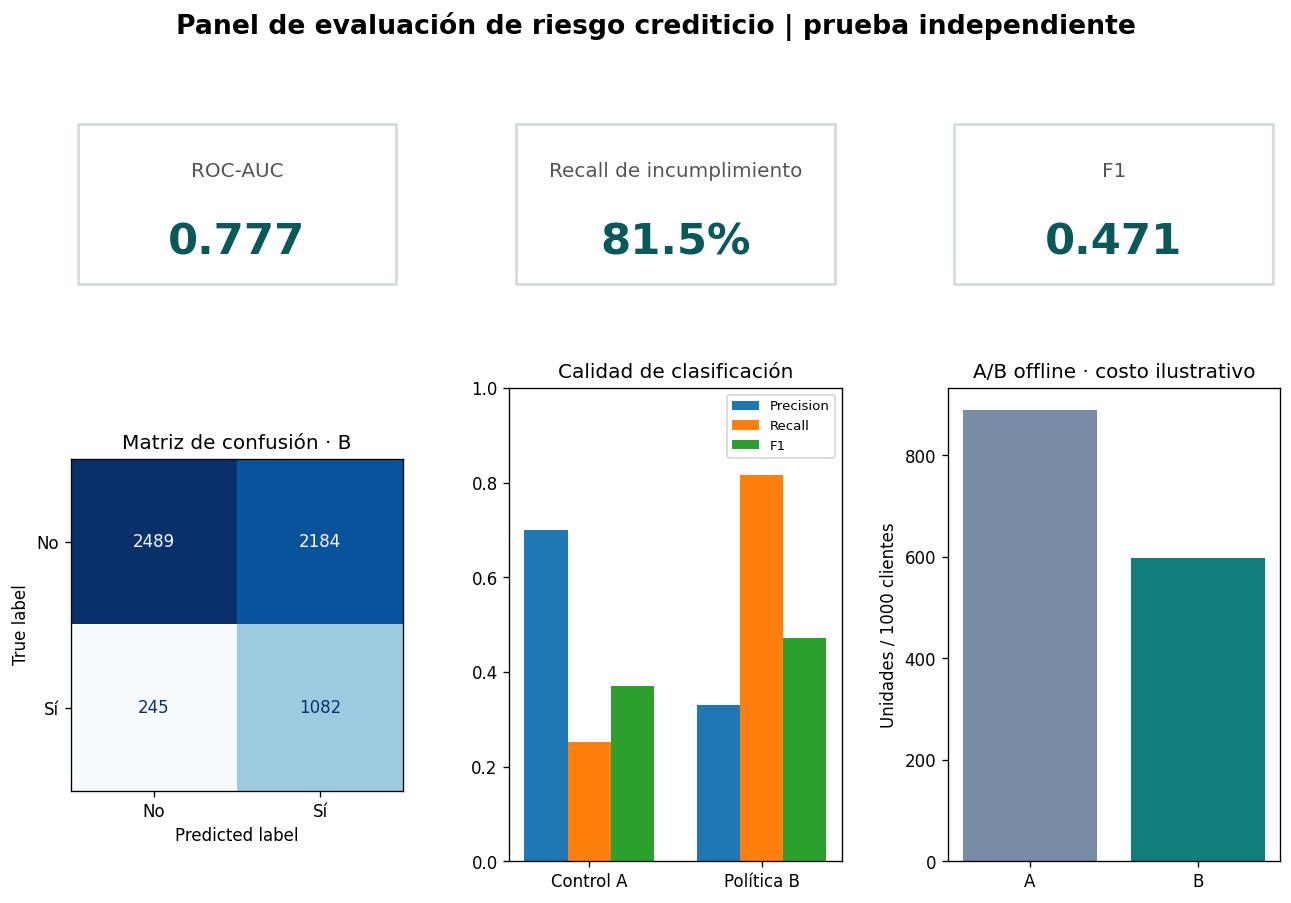

In [ ]:
principal = resumen_test.loc[resumen_test["politica"].str.contains("Seleccionado CV")].iloc[0]
control = resumen_test.loc[resumen_test["politica"] == "Logística | 0.50 (A)"].iloc[0]

fig = plt.figure(figsize=(13, 8))
cuadricula = fig.add_gridspec(2, 3, height_ratios=[0.9, 2.6], hspace=0.32, wspace=0.32)
indicadores = [
    ("ROC-AUC", principal["roc_auc"], ".3f"),
    ("Recall de incumplimiento", principal["recall"], ".1%"),
    ("F1", principal["f1"], ".3f"),
]
for idx, (etiqueta, valor, formato) in enumerate(indicadores):
    ax = fig.add_subplot(cuadricula[0, idx])
    ax.axis("off")
    ax.text(0.5, 0.70, etiqueta, ha="center", va="center", fontsize=12, color="#555")
    ax.text(0.5, 0.27, format(valor, formato), ha="center", va="center", fontsize=26, fontweight="bold", color="#09595a")
    ax.add_patch(plt.Rectangle((0.02, 0.01), 0.96, 0.98, transform=ax.transAxes, fill=False, edgecolor="#cfdadb", linewidth=1.5))

ax = fig.add_subplot(cuadricula[1, 0])
ConfusionMatrixDisplay(
    confusion_matrix(reales_test, pred_b_todos, labels=[0, 1]),
    display_labels=["No", "Sí"]
).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Matriz de confusión · B")

ax = fig.add_subplot(cuadricula[1, 1])
comparativo = resumen_test.set_index("politica").loc[["Logística | 0.50 (A)", f"Seleccionado CV | {umbral_optimo:.2f} (B)"]]
locs = np.arange(2)
ancho = 0.25
for i, metrica in enumerate(["precision", "recall", "f1"]):
    ax.bar(locs + (i - 1)*ancho, comparativo[metrica], width=ancho, label=metrica.title())
ax.set_xticks(locs, ["Control A", "Política B"])
ax.set_ylim(0, 1)
ax.set_title("Calidad de clasificación")
ax.legend(fontsize=8)

ax = fig.add_subplot(cuadricula[1, 2])
ax.bar(["A", "B"], [resultado_ab.loc["A", "costo_por_1000"], resultado_ab.loc["B", "costo_por_1000"]], color=["#778ba2", "#117e7c"])
ax.set_title("A/B offline · costo ilustrativo")
ax.set_ylabel("Unidades / 1000 clientes")
fig.suptitle("Panel de evaluación de riesgo crediticio | prueba independiente", fontsize=16, fontweight="bold", y=0.995)
fig.savefig(FIGURAS / "05_tablero_resumen.png", bbox_inches="tight")
plt.show()